# AirSense - 02 Pipeline, Experiments and Model Evaluation
Covers: the DVC pipeline and its run history, Ray throughput, the MLflow experiment table, and an evaluation of the final model on **future** data.
The production versions of these steps are `ingest.py`, `preprocess.py` and `train.py`; this notebook inspects their outputs.

In [1]:
import json, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mlflow, mlflow.sklearn
from sklearn.metrics import confusion_matrix, classification_report
from common import POLLUTANTS, CLASSES, FEATURES

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
print(subprocess.run(["dvc", "dag"], capture_output=True, text=True).stdout)

  +--------+   
  | ingest |   
  +--------+   
       *       
       *       
       *       
+------------+ 
| preprocess | 
+------------+ 
       *       
       *       
       *       
  +-------+    
  | train |    
  +-------+    



## 1. Pipeline DAG
Three DVC stages. `dvc repro` re-runs only stages whose code, params or data changed.

In [2]:
hist = pd.read_json("metrics/run_history.jsonl", lines=True)
print("Runs logged:", len(hist), "| success:", (hist.status == "success").sum(), "| failed:", (hist.status == "failed").sum())
hist[["started_at", "stage", "status", "seconds"]]

Runs logged: 6 | success: 6 | failed: 0


,started_at,stage,status,seconds
0,2026-11-07 07:31:31.510870+00:00,ingest,success,0.234
1,2026-11-07 07:31:32.437614+00:00,preprocess,success,9.702
2,2026-11-07 07:31:44.637551+00:00,train,success,18.284
3,2026-11-07 08:41:13.225728+00:00,ingest,success,0.402
4,2026-11-07 08:41:16.489182+00:00,preprocess,success,19.337
5,2026-11-07 08:41:41.584885+00:00,train,success,32.664


Engine: ray.data | rows: 24,850 | CPUs: 2
Transform throughput : 3,121 rows/s
End-to-end throughput: 1,286 rows/s (includes Ray start-up)


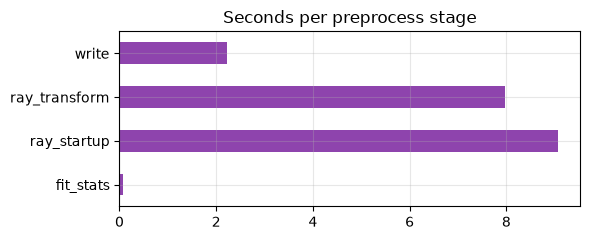

In [3]:
pm = json.load(open("metrics/pipeline_metrics.json"))
print(f"Engine: {pm['engine']} | rows: {pm['rows_in']:,} | CPUs: {pm['num_cpus']}")
print(f"Transform throughput : {pm['throughput_rows_per_sec_transform']:,.0f} rows/s")
print(f"End-to-end throughput: {pm['throughput_rows_per_sec_end_to_end']:,.0f} rows/s (includes Ray start-up)")
pd.Series(pm["stage_seconds"]).plot.barh(color="#8E44AD", figsize=(6, 2.5), title="Seconds per preprocess stage"); plt.tight_layout(); plt.show()

## 2. Ray data-engineering throughput
At this data size Ray's start-up dominates the end-to-end number; the transform itself is fast. With the full real dataset and more CPUs (`ray_num_cpus` in `params.yaml`) the ratio improves.

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
runs = mlflow.search_runs(experiment_names=["airsense"], order_by=["start_time ASC"])
cols = ["tags.mlflow.runName", "tags.role", "params.model", "metrics.val_macro_f1", "metrics.val_accuracy",
        "metrics.val_fit_seconds", "metrics.test_macro_f1", "tags.git_commit", "tags.dataset_md5", "tags.data_source"]
tbl = runs[[c for c in cols if c in runs]].rename(columns=lambda c: c.split(".")[-1])
tbl["git_commit"] = tbl["git_commit"].str[:10]; tbl["dataset_md5"] = tbl["dataset_md5"].str[:8]
tbl

,runName,role,model,val_macro_f1,val_accuracy,val_fit_seconds,test_macro_f1,git_commit,dataset_md5,data_source
0,candidate-logreg,candidate,logreg,0.565398,0.617541,2.212697,NaN,0c9fef357e,eef31a8d,real
1,candidate-random_forest,candidate,random_forest,0.698016,0.774930,2.622393,NaN,0c9fef357e,eef31a8d,real
2,candidate-hist_gb,candidate,hist_gb,0.667475,0.774529,1.875604,NaN,0c9fef357e,eef31a8d,real
3,final-random_forest,final,random_forest,NaN,NaN,NaN,0.769603,0c9fef357e,eef31a8d,real


## 3. Experiment tracking (MLflow)
Each candidate is a separate run; the **final** run holds the test metrics, artifacts and the model. Every run carries the Git commit and dataset hash, so any result can be reproduced with `git checkout <commit> && dvc repro`.
Model selection used the **validation** column only; the test set was touched once.

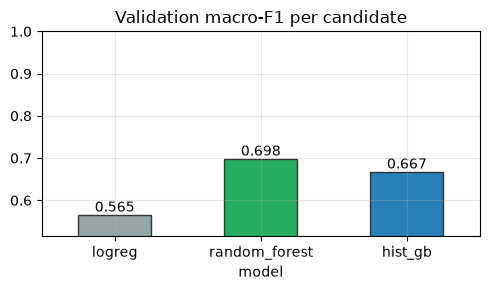

In [5]:
cand = tbl[tbl.role == "candidate"].set_index("model")["val_macro_f1"]
ax = cand.plot.bar(color=["#95A5A6", "#27AE60", "#2980B9"][:len(cand)], figsize=(5, 3), edgecolor="#333")
ax.set_ylim(min(cand) - .05, 1); ax.set_title("Validation macro-F1 per candidate"); plt.xticks(rotation=0)
for i, v in enumerate(cand): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [6]:
meta = json.load(open("models/model_meta.json"))
model = mlflow.sklearn.load_model("models/airsense_model")
test = pd.read_csv("data/processed/test.csv"); test["month"] = test["month"].astype(float)
pred = model.predict(test[FEATURES]); y = test["label"]
print("Selected model:", meta["model_name"], "| data source:", meta["data_source"], "| MLflow run:", meta["mlflow_run_id"])
print(classification_report(y, pred, labels=range(6), target_names=CLASSES, zero_division=0))

Selected model: random_forest | data source: real | MLflow run: 634b38429f4c4ef899a47fa6abe3ee5f
              precision    recall  f1-score   support

        Good       0.72      0.69      0.70       876
Satisfactory       0.81      0.84      0.83      3615
    Moderate       0.80      0.75      0.78      2541
        Poor       0.66      0.73      0.69       605
   Very Poor       0.77      0.76      0.76       358
      Severe       0.88      0.83      0.86       210

    accuracy                           0.79      8205
   macro avg       0.77      0.77      0.77      8205
weighted avg       0.79      0.79      0.79      8205



## 4. Final model on future data
Per-class precision/recall on the later-in-time test set. The acceptance gates are macro-F1 >= 0.80 and every recall >= 0.70.

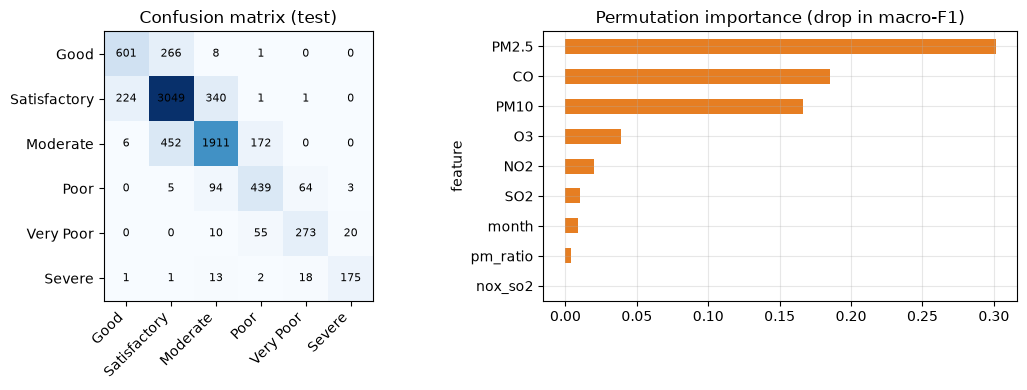

In [7]:
cm = confusion_matrix(y, pred, labels=range(6))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(cm, cmap="Blues"); axes[0].grid(False)
axes[0].set_xticks(range(6), CLASSES, rotation=45, ha="right"); axes[0].set_yticks(range(6), CLASSES); axes[0].set_title("Confusion matrix (test)")
for i in range(6):
    for j in range(6): axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
imp = pd.read_csv("metrics/feature_importance.csv").set_index("feature")["importance"].sort_values()
imp.plot.barh(ax=axes[1], color="#E67E22"); axes[1].set_title("Permutation importance (drop in macro-F1)")
plt.tight_layout(); plt.show()

## 5. Where do the mistakes happen, and what drives the model?
Errors should sit next to the diagonal (adjacent categories). Importance shows which readings matter, which can be sanity-checked against how CPCB defines AQI.

              mean  count
bin                      
(0.0, 0.5]   0.515    497
(0.5, 0.6]   0.611   1189
(0.6, 0.7]   0.714   1403
(0.7, 0.8]   0.815   1837
(0.8, 0.9]   0.887   2347
(0.9, 0.95]  0.947    870
(0.95, 1.0]  0.968     62


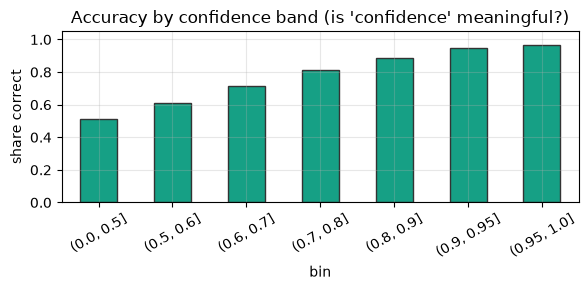

Predictions below the UI's 60% warning threshold: 20.5%


In [8]:
proba = model.predict_proba(test[FEATURES]); conf = proba.max(axis=1); ok = (model.classes_[proba.argmax(axis=1)] == y.values)
bins = pd.cut(conf, [0, .5, .6, .7, .8, .9, .95, 1.0])
calib = pd.DataFrame({"bin": bins, "correct": ok}).groupby("bin", observed=True)["correct"].agg(["mean", "count"])
print(calib.round(3))
ax = calib["mean"].plot.bar(color="#16A085", figsize=(6, 3), edgecolor="#333"); ax.set_ylim(0, 1.05)
ax.set_title("Accuracy by confidence band (is 'confidence' meaningful?)"); ax.set_ylabel("share correct"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
print(f"Predictions below the UI's 60% warning threshold: {(conf < .6).mean():.1%}")

## 6. Is the confidence score trustworthy?
If higher-confidence bands are more often correct, the number shown to users is meaningful. Low-confidence results trigger a yellow warning in the UI.

In [9]:
from ingest import sub_index, bucket
# Baseline: apply the OFFICIAL CPCB formula directly to the (imputed) pollutant values.
aqi = test[POLLUTANTS].apply(lambda col: col.map(lambda v, p=col.name: sub_index(p, v))).max(axis=1)
formula_pred = aqi.map(bucket).map({c: i for i, c in enumerate(CLASSES)})
print(f"CPCB formula on imputed inputs : accuracy = {(formula_pred == y).mean():.4f}")
print(f"Trained model                  : accuracy = {(pred == y).mean():.4f}")
gap = (pred == y).mean() - (formula_pred == y).mean()
print(f"\nModel minus formula accuracy: {gap:+.4f}")
print("The labels come from the formula applied to the ORIGINAL readings, so any error here is caused by imputed (missing) readings.")

CPCB formula on imputed inputs : accuracy = 0.7132
Trained model                  : accuracy = 0.7859

Model minus formula accuracy: +0.0726
The labels come from the formula applied to the ORIGINAL readings, so any error here is caused by imputed (missing) readings.


## 7. Honest conclusion: does the model beat the rule?
The official AQI is the maximum of per-pollutant sub-indices. Read the two accuracies above:

* **If the model is equal to (or below) the formula**, it adds no predictive value over simply applying the rule to the same imputed inputs. That is the expected outcome on the *synthetic* demo data, because its labels are produced by exactly this formula, so the formula is an upper bound there.
* **On the real Kaggle data** the labels follow CPCB's fuller procedure (averaging windows, minimum-pollutant rules), so the simple formula may *not* match them and a learned model could genuinely differ. Re-run `dvc repro` with the real CSV and re-run this notebook to find out; do not assume.

What the model does provide regardless: a **calibrated confidence score** (section 6), one consistent API for single and batch use, and a pipeline that can be retrained as data changes. Report both numbers honestly in your write-up.